# Ensemble Wars: The Aging Electronic Nose Challenge

**Goal:** classify 6 gases from 16 chemical sensors (128 features) and beat Macro-F1 = 0.73.
**Challenge:** sensor drift. Train = batches 1-7 (past), Test = batches 8-10 (future).
**Rules:** ensemble of classical ML only (no boosting / stacking / deep learning). 3 submissions.

## Step 1: Data Inspection
Before modelling we check shapes, columns, a possible batch column, class balance, missing values, feature scales, and whether the test file matches the submission format.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
sub = pd.read_csv("data/sample_submission.csv")

print("train:", train.shape)
print("test :", test.shape)
print("sub  :", sub.shape)

train: (9546, 131)
test : (4364, 130)
sub  : (4364, 2)


In [2]:
print("TRAIN columns (first 12):", list(train.columns[:12]))
print("TRAIN columns (last 8) :", list(train.columns[-8:]))
print("\nTEST columns (first 12):", list(test.columns[:12]))
print("TEST columns (last 8)  :", list(test.columns[-8:]))
print("\nSUB columns:", list(sub.columns))

# Columns that exist in train but not in test, and the reverse
print("\nIn train only:", sorted(set(train.columns) - set(test.columns)))
print("In test only :", sorted(set(test.columns) - set(train.columns)))

display(train.head(3))
display(test.head(3))
display(sub.head())

TRAIN columns (first 12): ['Id', 'batch', 'label', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9']
TRAIN columns (last 8) : ['feature_121', 'feature_122', 'feature_123', 'feature_124', 'feature_125', 'feature_126', 'feature_127', 'feature_128']

TEST columns (first 12): ['Id', 'batch', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10']
TEST columns (last 8)  : ['feature_121', 'feature_122', 'feature_123', 'feature_124', 'feature_125', 'feature_126', 'feature_127', 'feature_128']

SUB columns: ['Id', 'label']

In train only: ['label']
In test only : []


,Id,batch,label,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,...,feature_104,feature_105,feature_106,feature_107,feature_108,feature_109,feature_110,feature_111,feature_112,feature_113,feature_114,feature_115,feature_116,feature_117,feature_118,feature_119,feature_120,feature_121,feature_122,feature_123,feature_124,feature_125,feature_126,feature_127,feature_128
0,11813,7,6,18426.1433,8.012311,4.637280,6.854782,10.755495,-2.700655,-3.956627,-12.578918,60001.1811,9.185169,19.037836,31.073756,43.817302,-10.180689,-14.567102,-51.794764,9455.7353,2.143911,4.328490,8.011113,13.219457,-2.873599,...,-4.145275,4524.9141,2.658288,1.753655,4.349085,6.134449,-1.059858,-1.595048,-4.037912,20534.7680,3.899439,7.663424,13.259342,17.077281,-4.958672,-7.649273,-15.691021,20123.4307,4.265258,6.735639,11.602448,16.781786,-4.716063,-7.207139,-15.563540
1,875,7,4,12881.6084,4.999426,2.700797,3.776042,7.609812,-1.719600,-2.495682,-9.007950,48827.3765,8.520430,13.134772,19.428500,26.210236,-9.470144,-13.992189,-40.043661,13027.2441,3.941821,4.155823,7.683224,11.938263,-3.114100,...,-3.933707,4241.2029,2.981303,1.574671,4.074866,6.754963,-0.949168,-1.616586,-3.681582,20496.0463,4.571415,6.435583,11.424416,15.330592,-5.001582,-8.172268,-13.557608,17969.0107,4.448080,5.905540,10.604961,13.701524,-4.375042,-7.002332,-12.966454
2,428,3,3,21118.7700,5.584744,5.340035,7.677719,8.328934,-3.701702,-4.710054,-7.349776,24537.2915,5.515442,6.963726,11.254571,12.151727,-4.318954,-5.527645,-8.134413,21277.8037,2.940269,6.580070,8.802466,10.738280,-4.082372,...,-3.440048,7912.2928,3.169916,2.524308,3.860111,4.758274,-1.653787,-2.428173,-3.892334,18143.6084,2.864539,6.191953,9.389692,10.800147,-4.517436,-7.272255,-9.995701,15885.3477,2.842874,5.417050,8.220536,9.267007,-3.889974,-6.030040,-8.723799


,Id,batch,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,...,feature_104,feature_105,feature_106,feature_107,feature_108,feature_109,feature_110,feature_111,feature_112,feature_113,feature_114,feature_115,feature_116,feature_117,feature_118,feature_119,feature_120,feature_121,feature_122,feature_123,feature_124,feature_125,feature_126,feature_127,feature_128
0,2555,10,4202.4414,2.055342,3.372564,5.590404,7.739743,-0.387122,-0.722110,-3.618510,4036.6360,2.068386,4.004072,6.704694,9.733110,-0.412358,-0.812725,-4.130707,496.4087,1.199537,1.910007,6.373498,10.257176,-0.154450,-0.480085,...,-3.599665,474.8992,1.367616,1.189584,4.434674,9.062684,-0.092833,-0.406870,-3.341188,997.2695,1.338652,3.816391,12.584808,18.504904,-0.221473,-0.518221,-3.838885,887.2056,1.337105,3.537778,12.211809,18.160575,-0.208418,-0.504208,-3.024286
1,6408,8,620.0121,2.271340,0.134498,0.360341,2.315555,-0.063919,-0.293888,-2.472753,43262.2705,4.722080,9.116076,12.242956,18.702931,-6.918043,-10.567467,-38.029195,5926.4282,2.671502,1.435517,2.699808,4.824381,-1.057729,-1.796446,...,-2.989351,2394.9722,2.061308,0.706050,1.641895,3.345521,-0.417795,-0.757866,-3.299216,8948.5938,2.900126,2.063750,4.032992,6.561261,-1.617512,-2.533654,-6.587400,7813.5166,2.828960,1.841744,3.653183,6.228472,-1.419326,-2.174957,-5.234818
2,2345,10,33342.3457,2.727500,7.827400,11.069300,22.227100,-7.027100,-11.587500,-66.173500,32322.2305,2.178600,8.555600,13.324900,34.304500,-7.375200,-12.919900,-64.639700,10256.3508,3.829200,2.577800,4.338100,8.534300,-2.392100,-3.959600,...,-7.267600,2901.7283,2.433200,1.005900,2.473100,6.565600,-0.784900,-1.694500,-9.182100,14358.1191,3.965300,4.383700,7.848700,13.160000,-4.038200,-7.199000,-19.822400,12340.9634,3.841500,3.967900,7.079700,12.160800,-3.556500,-6.361600,-16.759000


,Id,label
0,2555,2
1,6408,2
2,2345,2
3,347,2
4,7030,2


### 1.2 Identify the key columns
Auto-detect the ID, target and batch columns, plus the feature columns. **Check that the printout matches what you saw above**, and edit the names manually if the guess is wrong.

In [3]:
# --- Auto-detect (edit manually if wrong) ---
ID_COL = "Id" if "Id" in train.columns else None

# target = column in train but not in test, and also not a batch column
candidates = [c for c in train.columns if c not in test.columns]
TARGET = "label" if "label" in train.columns else (candidates[0] if candidates else None)

# batch column: any column whose name contains 'batch'
batch_cols = [c for c in train.columns if "batch" in c.lower()]
BATCH = batch_cols[0] if batch_cols else None

# features = numeric columns shared by train and test, excluding id/target/batch
exclude = {c for c in [ID_COL, TARGET, BATCH] if c is not None}
FEATURES = [c for c in train.columns
            if c in test.columns and c not in exclude
            and pd.api.types.is_numeric_dtype(train[c])]

print("ID_COL   :", ID_COL)
print("TARGET   :", TARGET)
print("BATCH    :", BATCH)
print("n features:", len(FEATURES), "(expected 128)")

print("sample features:", FEATURES[:5])

ID_COL   : Id
TARGET   : label
BATCH    : batch
n features: 128 (expected 128)
sample features: ['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5']


### 1.3 Data quality: missing values, duplicates, dtypes, infinities
Anything dirty here would silently hurt SVM/KNN later, so we check it now.

In [4]:
print("Missing values  -> train:", train.isna().sum().sum(), "| test:", test.isna().sum().sum())
print("Infinite values -> train:", np.isinf(train[FEATURES]).sum().sum(),
      "| test:", np.isinf(test[FEATURES]).sum().sum())
print("Duplicate rows  -> train:", train.duplicated().sum(), "| test:", test.duplicated().sum())
print("Non-numeric feature columns:",
      [c for c in test.columns if c not in exclude and c not in FEATURES])

if ID_COL:
    print("\nDuplicate Ids   -> train:", train[ID_COL].duplicated().sum(),
          "| test:", test[ID_COL].duplicated().sum())
    print("Train Id range:", train[ID_COL].min(), "to", train[ID_COL].max())
    print("Test  Id range:", test[ID_COL].min(), "to", test[ID_COL].max())

print("\nFeature dtypes:\n", train[FEATURES].dtypes.value_counts())

Missing values  -> train: 0 | test: 0
Infinite values -> train: 0 | test: 0
Duplicate rows  -> train: 0 | test: 0
Non-numeric feature columns: []

Duplicate Ids   -> train: 0 | test: 0
Train Id range: 1 to 13910
Test  Id range: 3 to 13908

Feature dtypes:
 float64    128
Name: count, dtype: int64


### 1.4 Class balance
Macro-F1 gives each gas equal weight, so a small or weak class hurts a lot. We check how balanced the 6 classes are.

       count  percent
label                
1       1874    19.63
2       2241    23.48
3        901     9.44
4       1228    12.86
5       2188    22.92
6       1114    11.67

Imbalance ratio (max/min): 2.49


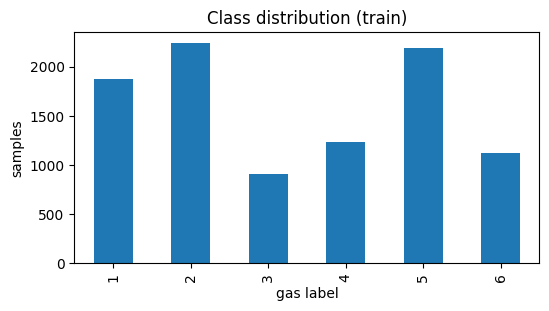

In [5]:
counts = train[TARGET].value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(2)
print(pd.DataFrame({"count": counts, "percent": pct}))
print("\nImbalance ratio (max/min):", round(counts.max() / counts.min(), 2))

counts.plot(kind="bar", figsize=(6, 3), title="Class distribution (train)")
plt.xlabel("gas label"); plt.ylabel("samples"); plt.show()

### 1.5 Batch structure (critical for validation)
If a batch column exists, we use it directly. If not, we check whether the Id or row order carries time information.

In [6]:
if BATCH:
    print("Train batches:\n", train[BATCH].value_counts().sort_index())
    if BATCH in test.columns:
        print("\nTest batches:\n", test[BATCH].value_counts().sort_index())
    print("\nClass counts per batch:")
    display(pd.crosstab(train[BATCH], train[TARGET]))
else:
    print("No batch column found.")
    print("Checking whether Id order is monotonic (could encode time):")
    if ID_COL:
        print("Train Id sorted ascending as stored:", train[ID_COL].is_monotonic_increasing)
        print("Test  Id sorted ascending as stored:", test[ID_COL].is_monotonic_increasing)
        print("Train Ids (first 15):", train[ID_COL].head(15).tolist())
        print("Test  Ids (first 15):", test[ID_COL].head(15).tolist())
    print("\nWe will try to infer batches in the next step.")

Train batches:
 batch
1     445
2    1244
3    1586
4     161
5     197
6    2300
7    3613
Name: count, dtype: int64

Test batches:
 batch
8      294
9      470
10    3600
Name: count, dtype: int64

Class counts per batch:


label,1,2,3,4,5,6
batch,,,,,,
1,90,98,83,30,70,74
2,164,334,100,109,532,5
3,365,490,216,240,275,0
4,64,43,12,30,12,0
5,28,40,20,46,63,0
6,514,574,110,29,606,467
7,649,662,360,744,630,568


### 1.6 Feature scales and drift
Check scales (SVM and KNN need scaling) and **how much each feature shifts between train and test**. This is the drift we must handle.

Feature range summary (train):
  min of means : -58.85
  max of means : 61355.18
  min of stds  : 0.47
  max of stds  : 75430.98
  constant features: 0

Mean |shift| across features (in train std units): 0.295
Median |shift|: 0.244
Features with |shift| > 1 std: 1 of 128

Top 10 most-drifted features:
feature_72     1.07
feature_80     0.92
feature_108    0.64
feature_107    0.62
feature_98     0.60
feature_121    0.59
feature_57     0.59
feature_106    0.58
feature_49     0.57
feature_105    0.57
dtype: float64


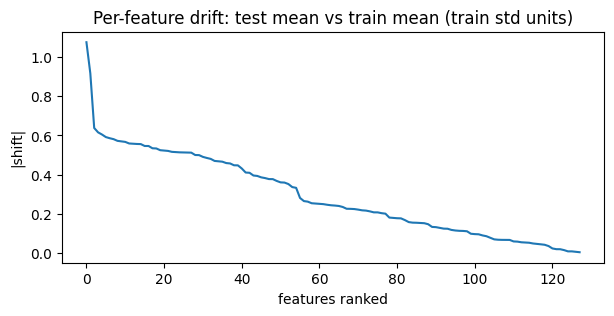

In [7]:
desc = train[FEATURES].describe().T
print("Feature range summary (train):")
print("  min of means :", round(float(desc["mean"].min()), 2))
print("  max of means :", round(float(desc["mean"].max()), 2))
print("  min of stds  :", round(float(desc["std"].min()), 2))
print("  max of stds  :", round(float(desc["std"].max()), 2))
print("  constant features:", int((desc["std"] == 0).sum()))

# Drift measure: shift of test mean from train mean, in train-std units
shift = ((test[FEATURES].mean() - train[FEATURES].mean()) / (train[FEATURES].std() + 1e-9)).abs()
print("\nMean |shift| across features (in train std units):", round(float(shift.mean()), 3))
print("Median |shift|:", round(float(shift.median()), 3))
print("Features with |shift| > 1 std:", int((shift > 1).sum()), "of", len(FEATURES))
print("\nTop 10 most-drifted features:")
print(shift.sort_values(ascending=False).head(10).round(2))

shift.sort_values(ascending=False).reset_index(drop=True).plot(
    figsize=(7, 3), title="Per-feature drift: test mean vs train mean (train std units)")
plt.ylabel("|shift|"); plt.xlabel("features ranked"); plt.show()

### 1.7 Submission format check
The test Ids must match `sample_submission.csv` exactly, since we will predict in this order.

In [8]:
if ID_COL:
    same_set = set(test[ID_COL]) == set(sub[ID_COL])
    same_order = (test[ID_COL].values == sub[ID_COL].values).all() if len(test) == len(sub) else False
    print("Test Ids == submission Ids (as set):", same_set)
    print("Same order as sample submission    :", same_order)
print("Rows -> test:", len(test), "| sample submission:", len(sub))
print("Sample submission label values:", sub["label"].unique()[:10])

Test Ids == submission Ids (as set): True
Same order as sample submission    : True
Rows -> test: 4364 | sample submission: 4364
Sample submission label values: [2]


### 1.8 Clean working copies

Build `X_train`, `y_train`, `X_test` and keep Ids for the submission. We **do not scale yet**. Scaling goes inside the validation pipeline so nothing leaks between folds.

In [9]:
X_train = train[FEATURES].copy()
y_train = train[TARGET].astype(int).copy()
X_test = test[FEATURES].copy()
test_ids = test[ID_COL].copy() if ID_COL else pd.Series(range(len(test)), name="Id")

# Defensive cleaning (should be no-ops if the data is clean)
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)
if X_train.isna().any().any() or X_test.isna().any().any():
    med = X_train.median()
    X_train = X_train.fillna(med)
    X_test = X_test.fillna(med)
    print("Filled NaNs with train medians.")

print("X_train:", X_train.shape, "| y_train:", y_train.shape, "| X_test:", X_test.shape)

print("Labels:", sorted(y_train.unique()))

X_train: (9546, 128) | y_train: (9546,) | X_test: (4364, 128)
Labels: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


## Step 2: Drift-aware validation (forward-chaining)

Random K-fold would mix time periods and give falsely high scores. Instead, each fold **trains on earlier batches and validates on later ones**.

| Fold | Train batches | Validate batch |
|---|---|---|
| F1 | 1-2 | 3 |
| F2 | 1-3 | 4-5 (combined; both tiny) |
| F3 | 1-5 | 6 |
| F4 | 1-6 | 7 |
| F5 (gap) | 1-5 | 7 (skips batch 6, mimics the larger gap to the test batches) |

Test is 82% batch 10, the furthest from training, so the later folds (F3-F5) matter most.

In [10]:
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.svm import SVC

Xtr_all = X_train.values.astype(float)
ytr_all = y_train.values
btr_all = train["batch"].values
Xte_all = X_test.values.astype(float)
bte_all = test["batch"].values

FOLDS = [
    ("F1: 1-2 -> 3",       [1, 2],          [3]),
    ("F2: 1-3 -> 4,5",     [1, 2, 3],       [4, 5]),
    ("F3: 1-5 -> 6",       [1, 2, 3, 4, 5], [6]),
    ("F4: 1-6 -> 7",       [1, 2, 3, 4, 5, 6], [7]),
    ("F5: 1-5 -> 7 (gap)", [1, 2, 3, 4, 5], [7]),
]

# Sanity check: no leakage, train batches strictly earlier than validation batches
for name, tr_b, va_b in FOLDS:
    assert max(tr_b) < min(va_b), f"Leak in {name}"
    n_tr = np.isin(btr_all, tr_b).sum()
    n_va = np.isin(btr_all, va_b).sum()
    print(f"{name:22s} train={n_tr:5d}  val={n_va:5d}")

F1: 1-2 -> 3           train= 1689  val= 1586
F2: 1-3 -> 4,5         train= 3275  val=  358
F3: 1-5 -> 6           train= 3633  val= 2300
F4: 1-6 -> 7           train= 5933  val= 3613
F5: 1-5 -> 7 (gap)     train= 3633  val= 3613


In [11]:
def signed_log(X):
    return np.sign(X) * np.log1p(np.abs(X))

def per_batch_zscore(X, batches):
    """Standardize each batch with its own mean/std. Uses features only, no labels."""
    out = np.empty_like(X, dtype=float)
    for b in np.unique(batches):
        m = batches == b
        mu = X[m].mean(axis=0)
        sd = X[m].std(axis=0) + 1e-9
        out[m] = (X[m] - mu) / sd
    return out

def preprocess(name, Xtr, btr, Xva, bva):
    """Return transformed (Xtr, Xva). Anything fitted uses the training part only."""
    if name == "standard":
        sc = StandardScaler().fit(Xtr)
        return sc.transform(Xtr), sc.transform(Xva)
    if name == "robust":
        sc = RobustScaler().fit(Xtr)
        return sc.transform(Xtr), sc.transform(Xva)
    if name == "slog+standard":
        A, B = signed_log(Xtr), signed_log(Xva)
        sc = StandardScaler().fit(A)
        return sc.transform(A), sc.transform(B)
    if name == "batchnorm":
        return per_batch_zscore(Xtr, btr), per_batch_zscore(Xva, bva)
    if name == "slog+batchnorm":
        return per_batch_zscore(signed_log(Xtr), btr), per_batch_zscore(signed_log(Xva), bva)
    raise ValueError(name)

In [12]:
def evaluate(model_factory, prep_name, verbose=False):
    """Forward-chaining evaluation. Returns list of (fold_name, macroF1, n_val)."""
    results = []
    for name, tr_b, va_b in FOLDS:
        tr = np.isin(btr_all, tr_b)
        va = np.isin(btr_all, va_b)
        Xa, Xb = preprocess(prep_name, Xtr_all[tr], btr_all[tr], Xtr_all[va], btr_all[va])
        model = model_factory()
        model.fit(Xa, ytr_all[tr])
        pred = model.predict(Xb)
        f1 = f1_score(ytr_all[va], pred, average="macro")
        results.append((name, f1, int(va.sum())))
        if verbose:
            print(f"  {name:22s} macroF1 = {f1:.4f}")
    return results

def summarize(results):
    f1s = np.array([r[1] for r in results])
    ns = np.array([r[2] for r in results])
    return f1s.mean(), (f1s * ns).sum() / ns.sum()

### Quick preprocessing comparison
One fast model (RBF-SVM, balanced class weights) across all 5 folds, to see **which preprocessing handles drift best** before building the ensemble. We report the plain mean and the size-weighted mean of Macro-F1.

In [13]:
import time

svm_factory = lambda: SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced")

prep_options = ["standard", "robust", "slog+standard", "batchnorm", "slog+batchnorm"]
rows = []
for p in prep_options:
    t0 = time.time()
    res = evaluate(svm_factory, p)
    mean_f1, w_f1 = summarize(res)
    row = {"preprocess": p}
    row.update({r[0]: round(r[1], 4) for r in res})
    row["mean"] = round(mean_f1, 4)
    row["weighted"] = round(w_f1, 4)
    rows.append(row)
    print(f"done {p:16s} in {time.time()-t0:.0f}s")

cmp_df = pd.DataFrame(rows).set_index("preprocess")
display(cmp_df)

done standard         in 2s
done robust           in 23s
done slog+standard    in 2s
done batchnorm        in 2s
done slog+batchnorm   in 2s


,F1: 1-2 -> 3,"F2: 1-3 -> 4,5",F3: 1-5 -> 6,F4: 1-6 -> 7,F5: 1-5 -> 7 (gap),mean,weighted
preprocess,,,,,,,
standard,0.9403,0.9291,0.6365,0.8773,0.6933,0.8153,0.7814
robust,0.5116,0.7828,0.2200,0.6066,0.3328,0.4908,0.4352
slog+standard,0.9349,0.9221,0.5926,0.8293,0.6007,0.7759,0.7273
batchnorm,0.7620,0.9173,0.6320,0.8341,0.6732,0.7637,0.7355
slog+batchnorm,0.7540,0.9230,0.6634,0.7798,0.6212,0.7483,0.7074


## Step 3: Base models (standard scaling, forward-chaining)

**Preprocessing decision:** StandardScaler (fit on training fold only). Robust scaling broke the RBF kernel, signed-log lost accuracy, and per-batch normalization failed because batches have very different gas mixes.

**Selection metric:** `late` = mean Macro-F1 of folds F3, F4, F5. These are the folds that mimic the real test, where drift is large. F1 and F2 are too easy and too small.

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# Scale each fold once (fit on the training part only) and cache it
FD = []
for name, tr_b, va_b in FOLDS:
    tr = np.isin(btr_all, tr_b); va = np.isin(btr_all, va_b)
    Xa, Xb = preprocess("standard", Xtr_all[tr], btr_all[tr], Xtr_all[va], btr_all[va])
    FD.append(dict(name=name, Xa=Xa, ya=ytr_all[tr], ba=btr_all[tr], Xb=Xb, yb=ytr_all[va]))

def run_cv(factory, decay=None):
    """Return per-fold macro-F1. decay<1 gives newer batches higher sample weight."""
    scores = []
    for d in FD:
        model = factory()
        if decay is None:
            model.fit(d["Xa"], d["ya"])
        else:
            w = decay ** (d["ba"].max() - d["ba"])
            model.fit(d["Xa"], d["ya"], sample_weight=w)
        scores.append(f1_score(d["yb"], model.predict(d["Xb"]), average="macro"))
    return scores

def row_from(scores, label):
    r = {"model": label}
    r.update({f"F{i+1}": round(s, 4) for i, s in enumerate(scores)})
    r["mean"] = round(float(np.mean(scores)), 4)
    r["late(F3-F5)"] = round(float(np.mean(scores[2:])), 4)
    return r

In [15]:
zoo = {
    "SVM rbf C=10": lambda: SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced"),
    "KNN k=5 dist": lambda: KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1),
    "RandomForest": lambda: RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                   n_jobs=-1, random_state=42),
    "ExtraTrees":   lambda: ExtraTreesClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                 n_jobs=-1, random_state=42),
    "Bagging DT":   lambda: BaggingClassifier(DecisionTreeClassifier(), n_estimators=100,
                                              n_jobs=-1, random_state=42),
    "Bagging KNN (subspace)": lambda: BaggingClassifier(KNeighborsClassifier(n_neighbors=5),
                                                        n_estimators=30, max_samples=0.8,
                                                        max_features=0.5, n_jobs=-1, random_state=42),
}

rows = []
for label, fac in zoo.items():
    t0 = time.time()
    rows.append(row_from(run_cv(fac), label))
    print(f"done {label:24s} {time.time()-t0:.0f}s")

base_df = pd.DataFrame(rows).set_index("model").sort_values("late(F3-F5)", ascending=False)

display(base_df)

done SVM rbf C=10             2s
done KNN k=5 dist             2s
done RandomForest             20s
done ExtraTrees               6s
done Bagging DT               73s
done Bagging KNN (subspace)   9s


,F1,F2,F3,F4,F5,mean,late(F3-F5)
model,,,,,,,
SVM rbf C=10,0.9403,0.9291,0.6365,0.8773,0.6933,0.8153,0.7357
ExtraTrees,0.9382,0.8904,0.6485,0.7772,0.6720,0.7852,0.6992
KNN k=5 dist,0.8960,0.7517,0.6068,0.7965,0.6175,0.7337,0.6736
Bagging KNN (subspace),0.8938,0.7605,0.5991,0.8035,0.6148,0.7343,0.6724
RandomForest,0.9345,0.7517,0.5988,0.7025,0.4976,0.6970,0.5997
Bagging DT,0.8246,0.6908,0.4749,0.7084,0.3492,0.6096,0.5109


### Drift idea 1: tune SVM `C` and `gamma`
Default `gamma="scale"` is about 0.0078 for standardized data. We try smaller gamma (smoother boundary, often more drift-tolerant) and larger gamma.

In [16]:
rows = []
for C in [1, 10, 100]:
    for g in [0.002, 0.0078, 0.03]:
        fac = lambda C=C, g=g: SVC(kernel="rbf", C=C, gamma=g, class_weight="balanced")
        rows.append(row_from(run_cv(fac), f"SVM C={C} g={g}"))

grid_df = pd.DataFrame(rows).set_index("model").sort_values("late(F3-F5)", ascending=False)
display(grid_df)

,F1,F2,F3,F4,F5,mean,late(F3-F5)
model,,,,,,,
SVM C=10 g=0.002,0.7560,0.9218,0.6385,0.8895,0.7014,0.7814,0.7431
SVM C=1 g=0.0078,0.7340,0.9425,0.6313,0.8967,0.6847,0.7778,0.7375
SVM C=100 g=0.002,0.8847,0.9271,0.6416,0.8675,0.6990,0.8040,0.7361
SVM C=10 g=0.0078,0.9403,0.9291,0.6365,0.8773,0.6935,0.8153,0.7358
SVM C=1 g=0.03,0.9302,0.8320,0.6288,0.8672,0.6779,0.7872,0.7246
SVM C=10 g=0.03,0.9005,0.7646,0.6112,0.8711,0.6665,0.7628,0.7163
SVM C=1 g=0.002,0.7091,0.9498,0.5894,0.8883,0.6587,0.7591,0.7121
SVM C=100 g=0.0078,0.9279,0.9372,0.5860,0.8541,0.6480,0.7907,0.6960
SVM C=100 g=0.03,0.8987,0.7646,0.5722,0.8257,0.6360,0.7395,0.6780


### Drift idea 2: recency weighting
Give recent batches higher sample weight: `weight = decay ** (latest_train_batch - batch)`. Decay of 1.0 means no weighting, and smaller values lean harder on the newest batches. Sensors drift gradually, so recent data should look more like the future.

In [17]:
# Requires cell 14 (FD, run_cv, row_from) to have been run
rec_models = {
    "SVM": lambda: SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced"),
    "RF":  lambda: RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                          n_jobs=-1, random_state=42),
    "ET":  lambda: ExtraTreesClassifier(n_estimators=300, class_weight="balanced_subsample",
                                        n_jobs=-1, random_state=42),
}

rows = []
for dec in [None, 0.9, 0.75, 0.6, 0.45]:
    for mname, fac in rec_models.items():
        rows.append(row_from(run_cv(fac, decay=dec), f"{mname} decay={dec}"))
        print("done", mname, dec)

rec_df = pd.DataFrame(rows).set_index("model")
display(rec_df.sort_values("late(F3-F5)", ascending=False))

done SVM None
done RF None
done ET None
done SVM 0.9
done RF 0.9
done ET 0.9
done SVM 0.75
done RF 0.75
done ET 0.75
done SVM 0.6
done RF 0.6
done ET 0.6
done SVM 0.45
done RF 0.45
done ET 0.45


,F1,F2,F3,F4,F5,mean,late(F3-F5)
model,,,,,,,
SVM decay=None,0.9403,0.9291,0.6365,0.8773,0.6933,0.8153,0.7357
SVM decay=0.45,0.9457,0.9290,0.6308,0.8631,0.7118,0.8161,0.7352
SVM decay=0.9,0.9416,0.9291,0.6362,0.8714,0.6933,0.8143,0.7336
SVM decay=0.6,0.9444,0.9267,0.6301,0.8623,0.7072,0.8142,0.7332
SVM decay=0.75,0.9423,0.9291,0.6315,0.8682,0.6971,0.8136,0.7323
ET decay=0.45,0.9362,0.8974,0.6430,0.7841,0.6708,0.7863,0.6993
ET decay=None,0.9382,0.8904,0.6485,0.7772,0.6720,0.7852,0.6992
ET decay=0.9,0.9379,0.8992,0.6471,0.7789,0.6684,0.7863,0.6982
ET decay=0.6,0.9383,0.8963,0.6469,0.7711,0.6707,0.7847,0.6962


In [18]:
print("=== BASE MODELS ===")
print(base_df.to_string())
print("\n=== SVM GRID ===")
print(grid_df.head(6).to_string())
print("\n=== RECENCY WEIGHTING ===")
print(rec_df.sort_values("late(F3-F5)", ascending=False).to_string())

=== BASE MODELS ===
                            F1      F2      F3      F4      F5    mean  late(F3-F5)
model                                                                              
SVM rbf C=10            0.9403  0.9291  0.6365  0.8773  0.6933  0.8153       0.7357
ExtraTrees              0.9382  0.8904  0.6485  0.7772  0.6720  0.7852       0.6992
KNN k=5 dist            0.8960  0.7517  0.6068  0.7965  0.6175  0.7337       0.6736
Bagging KNN (subspace)  0.8938  0.7605  0.5991  0.8035  0.6148  0.7343       0.6724
RandomForest            0.9345  0.7517  0.5988  0.7025  0.4976  0.6970       0.5997
Bagging DT              0.8246  0.6908  0.4749  0.7084  0.3492  0.6096       0.5109

=== SVM GRID ===
                       F1      F2      F3      F4      F5    mean  late(F3-F5)
model                                                                         
SVM C=10 g=0.002   0.7560  0.9218  0.6385  0.8895  0.7014  0.7814       0.7431
SVM C=1 g=0.0078   0.7340  0.9425  0.6313  0.8967  0.

## Step 4: Soft-voting ensemble

**Decisions from Step 3:** StandardScaler; no recency weighting. Dropped RandomForest and Bagging DT (collapse under drift).

**Pool:** two RBF-SVMs (different gamma), ExtraTrees, KNN, Bagging-KNN (random-subspace).

Each model is fit once per fold and its probabilities stored. We then evaluate every subset with equal weights, and a small weight grid on the best subset. Soft voting averages probabilities with fixed weights, so no meta-model is learned (not stacking).

In [20]:
POOL = {
    "SVM_g002":  lambda: SVC(kernel="rbf", C=10, gamma=0.002, class_weight="balanced",
                             probability=True, random_state=42),
    "SVM_g0078": lambda: SVC(kernel="rbf", C=10, gamma=0.0078, class_weight="balanced",
                             probability=True, random_state=42),
    "ET":        lambda: ExtraTreesClassifier(n_estimators=500, class_weight="balanced_subsample",
                                              n_jobs=-1, random_state=42),
    "KNN":       lambda: KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1),
    "BagKNN":    lambda: BaggingClassifier(KNeighborsClassifier(n_neighbors=5), n_estimators=30,
                                           max_samples=0.8, max_features=0.5,
                                           n_jobs=-1, random_state=42),
}
CLASSES = np.arange(1, 7)

def proba6(model, X):
    """Probabilities as an (n, 6) array, even if a class is missing from training."""
    out = np.zeros((len(X), 6))
    out[:, np.searchsorted(CLASSES, model.classes_)] = model.predict_proba(X)
    return out

P = {name: [] for name in POOL}
for d in FD:
    for name, fac in POOL.items():
        t0 = time.time()
        m = fac().fit(d["Xa"], d["ya"])
        P[name].append(proba6(m, d["Xb"]))
        
    print("done", d["name"])

done F1: 1-2 -> 3
done F2: 1-3 -> 4,5
done F3: 1-5 -> 6
done F4: 1-6 -> 7
done F5: 1-5 -> 7 (gap)


In [21]:
from itertools import combinations

def score_combo(weights):
    """weights: dict name -> weight. Returns per-fold macro-F1."""
    scores = []
    for i, d in enumerate(FD):
        blend = sum(w * P[n][i] for n, w in weights.items())
        pred = CLASSES[blend.argmax(axis=1)]
        scores.append(f1_score(d["yb"], pred, average="macro"))
    return scores

names = list(POOL)
rows = []
for k in range(1, len(names) + 1):
    for combo in combinations(names, k):
        s = score_combo({n: 1.0 for n in combo})
        rows.append(row_from(s, " + ".join(combo)))

combo_df = pd.DataFrame(rows).set_index("model").sort_values("late(F3-F5)", ascending=False)
display(combo_df.head(12))

,F1,F2,F3,F4,F5,mean,late(F3-F5)
model,,,,,,,
SVM_g002 + SVM_g0078,0.8941,0.9210,0.6427,0.8734,0.7071,0.8077,0.7410
SVM_g0078 + ET,0.9443,0.9582,0.6406,0.8740,0.7069,0.8248,0.7405
SVM_g002 + SVM_g0078 + ET,0.9250,0.9370,0.6424,0.8703,0.7067,0.8163,0.7398
SVM_g0078,0.9336,0.9124,0.6378,0.8837,0.6846,0.8104,0.7354
SVM_g002,0.7219,0.9322,0.6419,0.8565,0.7011,0.7707,0.7332
SVM_g002 + ET,0.7516,0.9367,0.6402,0.8543,0.7013,0.7768,0.7320
SVM_g002 + SVM_g0078 + ET + BagKNN,0.9172,0.9087,0.6360,0.8638,0.6856,0.8023,0.7285
SVM_g002 + SVM_g0078 + BagKNN,0.9128,0.8797,0.6359,0.8673,0.6796,0.7950,0.7276
SVM_g002 + SVM_g0078 + ET + KNN,0.9114,0.8703,0.6295,0.8544,0.6750,0.7881,0.7197


In [22]:
best_combo = combo_df.index[0].split(" + ")
print("Best equal-weight subset:", best_combo)

import itertools
grid = [0.5, 1.0, 2.0, 3.0]
rows = []
for ws in itertools.product(grid, repeat=len(best_combo)):
    s = score_combo(dict(zip(best_combo, ws)))
    rows.append(row_from(s, str(dict(zip(best_combo, ws)))))

wdf = pd.DataFrame(rows).set_index("model").sort_values("late(F3-F5)", ascending=False)
display(wdf.head(8))

Best equal-weight subset: ['SVM_g002', 'SVM_g0078']


,F1,F2,F3,F4,F5,mean,late(F3-F5)
model,,,,,,,
"{'SVM_g002': 0.5, 'SVM_g0078': 1.0}",0.9247,0.9118,0.6414,0.8771,0.7059,0.8122,0.7414
"{'SVM_g002': 1.0, 'SVM_g0078': 2.0}",0.9247,0.9118,0.6414,0.8771,0.7059,0.8122,0.7414
"{'SVM_g002': 2.0, 'SVM_g0078': 3.0}",0.9118,0.9138,0.6411,0.8750,0.7080,0.8100,0.7414
"{'SVM_g002': 1.0, 'SVM_g0078': 1.0}",0.8941,0.9210,0.6427,0.8734,0.7071,0.8077,0.7410
"{'SVM_g002': 2.0, 'SVM_g0078': 2.0}",0.8941,0.9210,0.6427,0.8734,0.7071,0.8077,0.7410
"{'SVM_g002': 3.0, 'SVM_g0078': 3.0}",0.8941,0.9210,0.6427,0.8734,0.7071,0.8077,0.7410
"{'SVM_g002': 0.5, 'SVM_g0078': 0.5}",0.8941,0.9210,0.6427,0.8734,0.7071,0.8077,0.7410
"{'SVM_g002': 1.0, 'SVM_g0078': 3.0}",0.9268,0.9096,0.6403,0.8788,0.7030,0.8117,0.7407


In [23]:
from sklearn.metrics import classification_report
best_w = eval(wdf.index[0])
print("Chosen weights:", best_w)

for i in [2, 3, 4]:
    d = FD[i]
    blend = sum(w * P[n][i] for n, w in best_w.items())
    pred = CLASSES[blend.argmax(axis=1)]
    print("\n", d["name"])
    print(classification_report(d["yb"], pred, digits=3, zero_division=0))

Chosen weights: {'SVM_g002': 0.5, 'SVM_g0078': 1.0}

 F3: 1-5 -> 6
              precision    recall  f1-score   support

           1      0.870     0.928     0.898       514
           2      1.000     0.911     0.954       574
           3      0.944     0.918     0.931       110
           4      0.054     1.000     0.102        29
           5      0.985     0.944     0.964       606
           6      0.000     0.000     0.000       467

    accuracy                          0.740      2300
   macro avg      0.642     0.784     0.641      2300
weighted avg      0.749     0.740     0.738      2300


 F4: 1-6 -> 7
              precision    recall  f1-score   support

           1      0.970     1.000     0.985       649
           2      0.770     1.000     0.870       662
           3      0.928     0.894     0.911       360
           4      1.000     0.589     0.741       744
           5      0.754     0.998     0.859       630
           6      0.996     0.815     0.896       

## Submission 1: SVM (gamma=0.0078) + ExtraTrees, equal-weight soft voting

Chosen by forward-chaining validation: best overall mean (0.825) and late-fold score (0.7405) among ensembles with genuinely different learners. Weight tuning gave no real gain over equal weights, so equal weights are used. Final fit uses all batches 1-7.

In [24]:
# Final fit on ALL training batches (1-7); scaler fitted on train only
sc = StandardScaler().fit(Xtr_all)
Xa = sc.transform(Xtr_all)
Xt = sc.transform(Xte_all)

final_models = ["SVM_g0078", "ET"]
probs = []
for n in final_models:
    m = POOL[n]().fit(Xa, ytr_all)
    probs.append(proba6(m, Xt))

blend = sum(probs)
pred = CLASSES[blend.argmax(axis=1)]

submission = pd.DataFrame({"Id": test_ids.values, "label": pred.astype(int)})
submission.to_csv("submission_1.csv", index=False)

# --- File checks ---
assert len(submission) == len(sub)
assert submission["Id"].is_unique
assert set(submission["Id"]) == set(sub["Id"])
assert submission["label"].between(1, 6).all()
print("submission_1.csv OK:", submission.shape)

print("\nPredicted class counts (all test):")
print(submission["label"].value_counts().sort_index())
print("\nPredicted class counts per test batch:")

display(pd.crosstab(test["batch"].values, submission["label"].values))

submission_1.csv OK: (4364, 2)

Predicted class counts (all test):
label
1    860
2    663
3    589
4    684
5    664
6    904
Name: count, dtype: int64

Predicted class counts per test batch:


col_0,1,2,3,4,5,6
row_0,,,,,,
8,32,25,27,36,158,16
9,68,55,102,172,73,0
10,760,583,460,476,433,888


In [25]:
display(pd.crosstab(train["batch"], train["label"]))

label,1,2,3,4,5,6
batch,,,,,,
1,90,98,83,30,70,74
2,164,334,100,109,532,5
3,365,490,216,240,275,0
4,64,43,12,30,12,0
5,28,40,20,46,63,0
6,514,574,110,29,606,467
7,649,662,360,744,630,568


## Step 5: Drift-robust feature selection
Assumed layout: 128 = 16 sensors x 8 feature types (feature_k -> sensor (k-1)//8, type (k-1)%8).
We drop one feature type (across all sensors) or one sensor at a time, and re-run forward-chaining with a fast SVM. Differences below about 0.01 are noise (only 3 late folds).

In [26]:
idx = np.arange(128)
sensor_of = idx // 8
type_of = idx % 8

def run_cv_cols(factory, cols):
    scores = []
    for d in FD:
        m = factory().fit(d["Xa"][:, cols], d["ya"])
        scores.append(f1_score(d["yb"], m.predict(d["Xb"][:, cols]), average="macro"))
    return scores

fast_svm = lambda: SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced")

rows = [row_from(run_cv_cols(fast_svm, idx), "ALL 128 features")]
for t in range(8):
    cols = idx[type_of != t]
    rows.append(row_from(run_cv_cols(fast_svm, cols), f"drop type {t}"))
for s in range(16):
    cols = idx[sensor_of != s]
    rows.append(row_from(run_cv_cols(fast_svm, cols), f"drop sensor {s}"))

abl = pd.DataFrame(rows).set_index("model")
display(abl.sort_values("late(F3-F5)", ascending=False))

,F1,F2,F3,F4,F5,mean,late(F3-F5)
model,,,,,,,
drop type 1,0.9701,0.9379,0.6471,0.8862,0.7036,0.8290,0.7456
drop sensor 13,0.9501,0.9267,0.6382,0.8899,0.6986,0.8207,0.7422
drop sensor 0,0.9402,0.9243,0.6368,0.8668,0.7214,0.8179,0.7417
drop type 3,0.9245,0.9296,0.6326,0.9062,0.6858,0.8157,0.7415
drop type 2,0.9540,0.9296,0.6380,0.8748,0.7084,0.8210,0.7404
drop sensor 12,0.9535,0.9296,0.6361,0.8905,0.6934,0.8206,0.7400
drop type 4,0.9409,0.9270,0.6365,0.8797,0.7007,0.8170,0.7390
drop sensor 6,0.9385,0.9266,0.6360,0.8756,0.7013,0.8156,0.7377
drop sensor 5,0.9484,0.9291,0.6391,0.8749,0.6956,0.8174,0.7365


## Step 6: Experiments for submission 2

**A. Feature subsets for the SVM + ExtraTrees ensemble.** Compare all 128 features against dropping feature type 1 (and types 1, 2).

**B. Self-training (drift adaptation).** For each validation fold: fit on the labeled training batches, predict the unlabeled later batch, add predictions with confidence >= threshold as extra training rows, refit, and predict again. Only unlabeled features and the model's own predictions are used, never test labels. Forward-chaining measures whether it really helps.

In [27]:
def ens_cv(cols, models=("SVM_g0078", "ET")):
    scores = []
    for d in FD:
        blend = 0
        for n in models:
            m = POOL[n]().fit(d["Xa"][:, cols], d["ya"])
            blend = blend + proba6(m, d["Xb"][:, cols])
        pred = CLASSES[blend.argmax(axis=1)]
        scores.append(f1_score(d["yb"], pred, average="macro"))
    return scores

variants = {
    "ALL 128":        idx,
    "drop type 1":    idx[type_of != 1],
    "drop types 1,2": idx[~np.isin(type_of, [1, 2])],
}
rows = []
for label, cols in variants.items():
    t0 = time.time()
    rows.append(row_from(ens_cv(cols), label))
    print(f"done {label} ({time.time()-t0:.0f}s)")
display(pd.DataFrame(rows).set_index("model"))

done ALL 128 (15s)
done drop type 1 (13s)
done drop types 1,2 (13s)


,F1,F2,F3,F4,F5,mean,late(F3-F5)
model,,,,,,,
ALL 128,0.9443,0.9582,0.6406,0.8740,0.7069,0.8248,0.7405
drop type 1,0.9587,0.9425,0.6544,0.9020,0.7057,0.8327,0.7540
"drop types 1,2",0.9719,0.9452,0.6588,0.9081,0.7061,0.8380,0.7576


In [28]:
def self_train_cv(cols, models=("SVM_g0078", "ET"), thr=0.9, rounds=1):
    scores, kept_frac = [], []
    for d in FD:
        Xa, ya, Xb = d["Xa"][:, cols], d["ya"], d["Xb"][:, cols]
        X_cur, y_cur = Xa, ya
        for r in range(rounds + 1):
            blend = 0
            for n in models:
                m = POOL[n]().fit(X_cur, y_cur)
                blend = blend + proba6(m, Xb)
            blend = blend / len(models)
            if r == rounds:
                break
            conf = blend.max(axis=1)
            lab = CLASSES[blend.argmax(axis=1)]
            keep = conf >= thr
            kept_frac.append(keep.mean())
            X_cur = np.vstack([Xa, Xb[keep]])
            y_cur = np.concatenate([ya, lab[keep]])
        scores.append(f1_score(d["yb"], CLASSES[blend.argmax(axis=1)], average="macro"))
    return scores, float(np.mean(kept_frac))

rows = []
for thr in [0.7, 0.9]:
    t0 = time.time()
    s, kf = self_train_cv(idx, thr=thr)
    rows.append(row_from(s, f"self-train thr={thr} (kept {kf:.0%})"))
    print(f"done thr={thr} ({time.time()-t0:.0f}s)")

st_df = pd.DataFrame(rows).set_index("model")
display(st_df)
print("Reference, no self-training: SVM_g0078 + ET -> F3 0.6406, F4 0.8740, F5 0.7069, late 0.7405")

done thr=0.7 (34s)
done thr=0.9 (32s)


,F1,F2,F3,F4,F5,mean,late(F3-F5)
model,,,,,,,
self-train thr=0.7 (kept 67%),0.9611,0.9585,0.6531,0.860,0.7215,0.8308,0.7449
self-train thr=0.9 (kept 30%),0.9443,0.9585,0.6429,0.867,0.6955,0.8216,0.7351


Reference, no self-training: SVM_g0078 + ET -> F3 0.6406, F4 0.8740, F5 0.7069, late 0.7405


## Submission 2: SVM (gamma=0.0078) + ExtraTrees on drift-robust features

Drops feature types 1 and 2 (all 16 sensors, 32 columns), keeping 96 features. Forward-chaining: late score 0.7576 vs 0.7405 with all features, with gains in F3 and F4. Self-training was tested and rejected (no reliable gain). Same models, equal weights, fit on all batches 1-7.

In [29]:
cols_red = idx[~np.isin(type_of, [1, 2])]
print("features kept:", len(cols_red))

sc = StandardScaler().fit(Xtr_all)
Xa = sc.transform(Xtr_all)[:, cols_red]
Xt = sc.transform(Xte_all)[:, cols_red]

probs = []
for n in ["SVM_g0078", "ET"]:
    m = POOL[n]().fit(Xa, ytr_all)
    probs.append(proba6(m, Xt))

pred2 = CLASSES[sum(probs).argmax(axis=1)]
submission2 = pd.DataFrame({"Id": test_ids.values, "label": pred2.astype(int)})
submission2.to_csv("submission_2.csv", index=False)

# --- File checks ---
assert len(submission2) == len(sub)
assert submission2["Id"].is_unique
assert set(submission2["Id"]) == set(sub["Id"])
assert submission2["label"].between(1, 6).all()
print("submission_2.csv OK:", submission2.shape)

# --- How different is it from submission 1? ---
s1 = pd.read_csv("submission_1.csv")
assert (s1["Id"].values == submission2["Id"].values).all()
print("Labels changed vs submission 1: %.1f%%" % (100 * (s1["label"].values != pred2).mean()))
print("\nPredicted counts per test batch:")
display(pd.crosstab(test["batch"].values, submission2["label"].values))

features kept: 96
submission_2.csv OK: (4364, 2)
Labels changed vs submission 1: 18.5%

Predicted counts per test batch:


col_0,1,2,3,4,5,6
row_0,,,,,,
8,31,26,28,36,157,16
9,64,53,107,171,73,2
10,726,539,497,900,492,446


In [30]:
base = [1, 2]
rows = [row_from(ens_cv(idx[~np.isin(type_of, base)]), "drop 1,2 (current)")]
for t in [0, 3, 4, 5, 6, 7]:
    cols = idx[~np.isin(type_of, base + [t])]
    rows.append(row_from(ens_cv(cols), f"drop 1,2,{t}"))
    print("done type", t)

display(pd.DataFrame(rows).set_index("model").sort_values("late(F3-F5)", ascending=False))

done type 0
done type 3
done type 4
done type 5
done type 6
done type 7


,F1,F2,F3,F4,F5,mean,late(F3-F5)
model,,,,,,,
"drop 1,2 (current)",0.9719,0.9452,0.6588,0.9081,0.7061,0.8380,0.7576
"drop 1,2,4",0.9421,0.9551,0.6509,0.9168,0.7014,0.8332,0.7563
"drop 1,2,6",0.9677,0.9535,0.6528,0.8959,0.6986,0.8337,0.7491
"drop 1,2,7",0.9731,0.9011,0.6515,0.9078,0.6744,0.8216,0.7446
"drop 1,2,3",0.9260,0.9558,0.6386,0.9190,0.6753,0.8229,0.7443
"drop 1,2,5",0.9733,0.9478,0.6470,0.8898,0.6941,0.8304,0.7437
"drop 1,2,0",0.9583,0.8984,0.6622,0.7919,0.7115,0.8045,0.7219


## Submission 3 candidates (judged mainly on F4 and F5)
Submission 2 (reduced features) scored 0.700 on Kaggle vs 0.755 for submission 1, so validation on F3-F4 misled us. F5 (largest time gap) is the closest proxy for test batch 10, so it gets the most weight now.

Candidates: (a) blend of full-feature and reduced-feature ensembles, (b) pooled scaling (scaler fit on train + unlabeled future-batch features; no labels used).

In [31]:
def fold_probs(cols, models=("SVM_g0078", "ET")):
    out = []
    for d in FD:
        b = 0
        for n in models:
            m = POOL[n]().fit(d["Xa"][:, cols], d["ya"])
            b = b + proba6(m, d["Xb"][:, cols])
        out.append(b / len(models))
    return out

PF = fold_probs(idx)         # full 128 features
PR = fold_probs(cols_red)    # 96 features (types 1,2 dropped)

# (b) pooled scaling: scaler sees unlabeled validation features
PP = []
for name, tr_b, va_b in FOLDS:
    tr = np.isin(btr_all, tr_b); va = np.isin(btr_all, va_b)
    sc_p = StandardScaler().fit(np.vstack([Xtr_all[tr], Xtr_all[va]]))
    Xa_p, Xb_p = sc_p.transform(Xtr_all[tr]), sc_p.transform(Xtr_all[va])
    b = 0
    for n in ["SVM_g0078", "ET"]:
        b = b + proba6(POOL[n]().fit(Xa_p, ytr_all[tr]), Xb_p)
    PP.append(b / 2)

def score_probs(plist):
    return [f1_score(d["yb"], CLASSES[p.argmax(axis=1)], average="macro")
            for d, p in zip(FD, plist)]

rows = [
    row_from(score_probs(PF), "full (= submission 1)"),
    row_from(score_probs(PR), "reduced (= submission 2)"),
    row_from(score_probs([(a + b) / 2 for a, b in zip(PF, PR)]), "blend full+reduced 1:1"),
    row_from(score_probs([(2 * a + b) / 3 for a, b in zip(PF, PR)]), "blend full:reduced 2:1"),
    row_from(score_probs(PP), "pooled scaling"),
    row_from(score_probs([(a + b) / 2 for a, b in zip(PF, PP)]), "full + pooled 1:1"),
]
display(pd.DataFrame(rows).set_index("model"))

# Per-class F1 on F4 and F5 for full vs reduced: which class lost?
for i in [3, 4]:
    pf = f1_score(FD[i]["yb"], CLASSES[PF[i].argmax(axis=1)], average=None, labels=CLASSES)
    pr = f1_score(FD[i]["yb"], CLASSES[PR[i].argmax(axis=1)], average=None, labels=CLASSES)
    print(FD[i]["name"])
    print(pd.DataFrame({"full": pf.round(3), "reduced": pr.round(3)}, index=CLASSES).T)

,F1,F2,F3,F4,F5,mean,late(F3-F5)
model,,,,,,,
full (= submission 1),0.9443,0.9582,0.6406,0.8740,0.7069,0.8248,0.7405
reduced (= submission 2),0.9719,0.9452,0.6588,0.9081,0.7061,0.8380,0.7576
blend full+reduced 1:1,0.9467,0.9532,0.6468,0.8976,0.7034,0.8295,0.7493
blend full:reduced 2:1,0.9455,0.9558,0.6451,0.8919,0.7059,0.8288,0.7476
pooled scaling,0.9300,0.9558,0.6415,0.8737,0.7091,0.8220,0.7414
full + pooled 1:1,0.9403,0.9582,0.6406,0.8735,0.7075,0.8240,0.7405


F4: 1-6 -> 7
             1      2      3     4      5      6
full     0.992  0.869  0.920  0.73  0.839  0.893
reduced  0.997  0.852  0.932  0.80  0.929  0.938
F5: 1-5 -> 7 (gap)
             1      2      3      4      5    6
full     0.758  0.957  0.954  0.644  0.929  0.0
reduced  0.824  0.975  0.943  0.609  0.886  0.0


## Submission 3: pooled scaling (SVM + ExtraTrees, all 128 features)
Same ensemble as submission 1, but the StandardScaler is fit on train + unlabeled test features, a mild drift correction (no labels used). Forward-chaining: F4 0.8737, F5 0.7091 vs 0.8740 / 0.7069 for submission 1, i.e. a tie, so any gain is expected to be small. Reduced-feature models (submission 2) validated better but scored 0.700 on Kaggle, so we do not trust fine feature selection under this validation.

In [32]:
sc_p = StandardScaler().fit(np.vstack([Xtr_all, Xte_all]))
Xa_p = sc_p.transform(Xtr_all)
Xt_p = sc_p.transform(Xte_all)

probs = []
for n in ["SVM_g0078", "ET"]:
    probs.append(proba6(POOL[n]().fit(Xa_p, ytr_all), Xt_p))
pred3 = CLASSES[sum(probs).argmax(axis=1)]

submission3 = pd.DataFrame({"Id": test_ids.values, "label": pred3.astype(int)})
submission3.to_csv("submission_3.csv", index=False)

# --- File checks ---
assert len(submission3) == len(sub)
assert submission3["Id"].is_unique
assert set(submission3["Id"]) == set(sub["Id"])
assert submission3["label"].between(1, 6).all()
print("submission_3.csv OK:", submission3.shape)

s1 = pd.read_csv("submission_1.csv")
assert (s1["Id"].values == submission3["Id"].values).all()
print("Labels changed vs submission 1: %.1f%%" % (100 * (s1["label"].values != pred3).mean()))
print("\nPredicted counts per test batch:")
display(pd.crosstab(test["batch"].values, submission3["label"].values))

submission_3.csv OK: (4364, 2)
Labels changed vs submission 1: 5.5%

Predicted counts per test batch:


col_0,1,2,3,4,5,6
row_0,,,,,,
8,32,27,27,35,157,16
9,68,55,102,172,72,1
10,711,591,458,559,443,838
